In [26]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, confusion_matrix, roc_auc_score, classification_report
)
import joblib
import os
print("leb done")

leb done


In [27]:
data = pd.read_csv("/content/spam.csv")
print("data load")

print(data.head())
print(data.shape)


data load
      email_id                   sender                   subject  \
0  EMAIL000001       offers@example.com         You are a winner!   
1  EMAIL000002  student@college.example               Class notes   
2  EMAIL000003  student@college.example            Meeting update   
3  EMAIL000004  support@service.example  Appointment confirmation   
4  EMAIL000005        team@work.example  Appointment confirmation   

                                          email_text     label  
0       Get a free phone by entering our prize draw.      spam  
1  Please review the document before Friday. Than...  not spam  
2      Please let me know if you have any questions.  not spam  
3     Happy birthday! Hope you have a wonderful day.  not spam  
4  Hi, can we move our meeting to tomorrow aftern...  not spam  
(11927, 5)


# missing value


In [28]:
print("missing value \n" , data.isnull().sum())

# duplicates

print("duplicates \n" , data[data.duplicated()])  # duplicated ().sum()

missing value 
 email_id       0
sender        91
subject       85
email_text    16
label          0
dtype: int64
duplicates 
 Empty DataFrame
Columns: [email_id, sender, subject, email_text, label]
Index: []


# **remove duplicate rows ****

In [29]:
df = data.drop_duplicates().copy()
print("remove duplicate \n" , df)


remove duplicate 
           email_id                     sender                   subject  \
0      EMAIL000001         offers@example.com         You are a winner!   
1      EMAIL000002    student@college.example               Class notes   
2      EMAIL000003    student@college.example            Meeting update   
3      EMAIL000004    support@service.example  Appointment confirmation   
4      EMAIL000005          team@work.example  Appointment confirmation   
...            ...                        ...                       ...   
11922  EMAIL011923    support@service.example  Appointment confirmation   
11923  EMAIL011924    support@service.example  Appointment confirmation   
11924  EMAIL011925    student@college.example            Project update   
11925  EMAIL011926  colleague@company.example            Project update   
11926  EMAIL011927  colleague@company.example       Document for review   

                                              email_text     label  
0          

# Fill missing value

In [30]:
df["sender"] = df["sender"].fillna("")
df["subject"] = df["subject"].fillna("")
df["email_text"] = df["email_text"].fillna("")

print("clean data \n", df.shape)
print("missing \n" , df.duplicated().sum())
print("null value \n " ,df.isnull().sum())

clean data 
 (11927, 5)
missing 
 0
null value 
  email_id      0
sender        0
subject       0
email_text    0
label         0
dtype: int64


# Target and features

In [31]:
# Combine sender, subject, and email text
x = (
    df["sender"].fillna("") + " " +
    df["subject"].fillna("") + " " +
    df["email_text"].fillna("")
)

# Select target column
y = df["label"]

# Display features and target
print(x.head())
print(y.value_counts())

0    offers@example.com You are a winner! Get a fre...
1    student@college.example Class notes Please rev...
2    student@college.example Meeting update Please ...
3    support@service.example Appointment confirmati...
4    team@work.example Appointment confirmation Hi,...
dtype: object
label
spam        6131
not spam    5796
Name: count, dtype: int64


Vi****sulization****

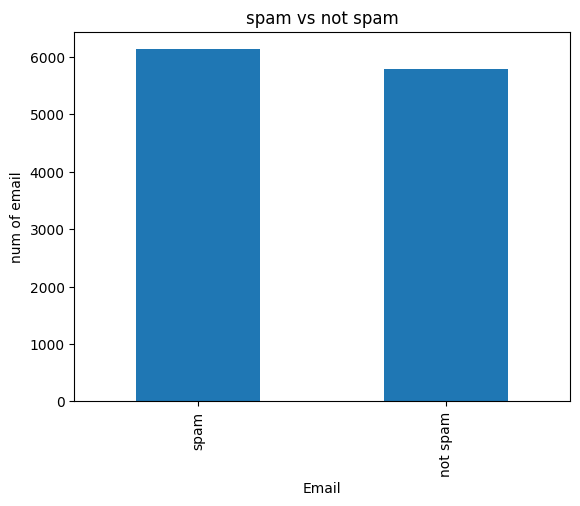

In [32]:
visual = y.value_counts()
visual.plot(kind="bar")
plt.title("spam vs not spam")
plt.xlabel("Email")
plt.ylabel("num of email")
plt.show()


** train test phase**********


In [33]:
x_train , x_test , y_train , y_test = train_test_split(
    x ,
    y ,
    test_size = 0.2,
    random_state = 42,
    stratify = y
)
print ("training sample:" , len(x_train))
print ("testing sample : " ,len(x_test))


model = Pipeline([
    ("text convert into numerical" , TfidfVectorizer()),
    ("classification model" , LogisticRegression(max_iter = 1000))
])

model.fit(x_train ,y_train)


training sample: 9541
testing sample :  2386


Pipeline(steps=[('text convert into numerical', TfidfVectorizer()),
                ('classification model', LogisticRegression(max_iter=1000))])

In [34]:
y_prediction = model.predict(x_test)
print("model pridiction ")

print ("\n confussion matrix")
print(confusion_matrix(y_test , y_prediction))

print("\nClassification Report")
print(classification_report(y_test, y_prediction, zero_division=0))

print("\n Prcision" , precision_score(y_test , y_prediction ,pos_label="spam", zero_division=0)*100 , "%")
print("\n recall " , recall_score (y_test , y_prediction ,pos_label="spam", zero_division=0)*100,"%")
print("\n f1-score" , f1_score(y_test , y_prediction ,pos_label="spam", zero_division=0)*100 , "%")
accuracy = accuracy_score(y_test , y_prediction)
print("accuracy of model" , accuracy*100 , "%")


model pridiction 

 confussion matrix
[[1159    0]
 [   0 1227]]

Classification Report
              precision    recall  f1-score   support

    not spam       1.00      1.00      1.00      1159
        spam       1.00      1.00      1.00      1227

    accuracy                           1.00      2386
   macro avg       1.00      1.00      1.00      2386
weighted avg       1.00      1.00      1.00      2386


 Prcision 100.0 %

 recall  100.0 %

 f1-score 100.0 %
accuracy of model 100.0 %


saving model


In [35]:
joblib.dump(model, "spam___model.ipynb")

print("Full file path:", os.path.abspath("spam_model.ipynb"))
print("File exists:", os.path.exists("spam_model.ipynb"))

sender = input("Enter sender email: ")
subject = input("Enter email subject: ")
email_text = input("Enter email content: ")

new_email = sender + " " + subject + " " + email_text

prediction = model.predict([new_email])

if prediction[0] == "spam":
    print("Result: Spam Email")
else:
    print("Result: Not Spam Email")

Full file path: /content/spam_model.ipynb
File exists: False
Enter sender email: harshtiwari930500@gmail.com
Enter email subject: price
Enter email content: heelo sir
Result: Spam Email


In [36]:
# Import joblib
import joblib

# Save trained model
joblib.dump(model, "spam_model.joblib")

print("Model saved successfully!")

Model saved successfully!


In [37]:
from google.colab import files

files.download("spam_model.joblib")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

**# Experiment 2: Real data (Enron)**

In [38]:
import pandas as pd

url = "https://huggingface.co/datasets/SetFit/enron_spam/resolve/main/enron_spam_data.csv"
df = pd.read_csv(url).fillna("")

df["text"] = df["Subject"] + " " + df["Message"]
df["label"] = df["Spam/Ham"]
df = df[df["text"].str.strip() != ""].drop_duplicates(subset="text")

print(df.shape)
print(df["label"].value_counts())

(30493, 7)
label
ham     15910
spam    14583
Name: count, dtype: int64


In [39]:
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix

x_train, x_test, y_train, y_test = train_test_split(
    df["text"], df["label"], test_size=0.2,
    random_state=42, stratify=df["label"])

model = Pipeline([
    ("tfidf", TfidfVectorizer()),
    ("clf", LogisticRegression(max_iter=1000))
])
model.fit(x_train, y_train)

pred = model.predict(x_test)
print(confusion_matrix(y_test, pred))
print(classification_report(y_test, pred, digits=4))

[[3112   70]
 [  10 2907]]
              precision    recall  f1-score   support

         ham     0.9968    0.9780    0.9873      3182
        spam     0.9765    0.9966    0.9864      2917

    accuracy                         0.9869      6099
   macro avg     0.9866    0.9873    0.9869      6099
weighted avg     0.9871    0.9869    0.9869      6099



**# Experiment 3: Hard test**

In [40]:
test = pd.read_csv("/content/hard_test_emails.csv")
test["label"] = test["label"].replace("not spam", "ham")

pred = model.predict(test["subject"] + " " + test["email_text"])
print(confusion_matrix(test["label"], pred))
print(classification_report(test["label"], pred, digits=4))

[[ 9 11]
 [ 2 18]]
              precision    recall  f1-score   support

         ham     0.8182    0.4500    0.5806        20
        spam     0.6207    0.9000    0.7347        20

    accuracy                         0.6750        40
   macro avg     0.7194    0.6750    0.6577        40
weighted avg     0.7194    0.6750    0.6577        40



In [41]:
import joblib
from google.colab import files

joblib.dump(model, "spam_model_enron.joblib")
files.download("spam_model_enron.joblib")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>